# MRAF y la región de señal

**Pregunta:** ¿Cómo cambia la libertad de amplitud en región mixta (MRAF) eficiencia por un potencial moldeado preciso, en un disco y en un anillo, y hasta dónde puede llegar el parámetro de mezcla?

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** notebook 01 del tema 03
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Un arreglo de trampas quiere luz en puntos. Un potencial moldeado, un disco, un anillo o una línea, quiere luz repartida sobre una región con un perfil prescrito, y el experimento se preocupa del perfil: un disco plano atrapa un gas con densidad uniforme, un anillo lleva una corriente persistente. Gerchberg-Saxton simple, ejecutado con la forma como objetivo y cero en todo lo demás, da un perfil pobre, y la libertad de amplitud en región mixta (MRAF) da uno bueno al dejar que parte de la luz vaya a otra parte. Medirás ambos en un disco y en un anillo, recorrerás el parámetro de mezcla para ver de dónde viene la precisión y qué cuesta, y probarás la única elección que el método deja a quien lo usa, el inicio.

## Preparación

El entorno de los notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este notebook, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 scipy==1.18.1 slmsuite==0.5.0
```

DinHot no publica ningún paquete propio: sus métodos viven en `data-pipeline/pipeline/` y el notebook los importa por su ruta. La celda siguiente importa las herramientas, imprime sus versiones y pone el pipeline en la ruta.

In [1]:
# the tools and their versions, then the pipeline's modules by path
import copy
import importlib.metadata as md
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import ndimage

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of, target_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, geometry
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m04_gs, m08_mraf
import slmsuite
from slmsuite.holography.algorithms import Hologram

slmsuite.configure_logging(None)  # no console log inside the outputs

for name in ("numpy", "matplotlib", "scipy", "slmsuite"):
    print(name, md.version(name))


def shape_numbers(phi, target, setup):
    # shape error (Pasienski and DeMarco Eq. 2, eroded shape) and the power fraction in the signal region
    field = forward.fft_focal_field(phi, setup)
    core = ndimage.binary_erosion(target.amplitude > 0, structure=np.ones((2 * setup.pad + 1,) * 2))
    wanted = target.amplitude[core] ** 2
    got = np.abs(field[core]) ** 2
    scale = wanted.sum() / got.sum()
    error = np.sqrt(np.mean(((scale * got - wanted) / wanted) ** 2))
    return error, np.sum(np.abs(field[target.mask]) ** 2) / setup.n_pix**2

numpy 2.4.6
matplotlib 3.11.2
scipy 1.18.1
slmsuite 0.5.0


## Datos

- Propietario: este repositorio, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Clase de licencia: caso sintético escrito por el producto, ningún conjunto de datos de terceros, cubierto por la licencia del repositorio.
- Archivo leído: `data/examples/cases.json`, caso C04: un disco de 15 um de radio sobre el SLM de 256 por 256 píxeles, cuyo dispositivo (4 bits y crosstalk) no se usa aquí; una copia de su registro con un anillo de 20 um de radio y 8 um de ancho da la segunda forma.

In [2]:
# case C04 gives the SLM, the beam and the disc; a copy of its record with a ring target gives the second shape
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec_disc = records["C04_disc_crosstalk"]
rec_ring = copy.deepcopy(rec_disc)
rec_ring["target"] = {"kind": "shaped", "shape": "ring", "radius_um": 20.0, "width_um": 8.0, "signal_margin_bins": 3}
setup = setup_of(rec_disc)
shapes = {"disc": target_of(rec_disc), "ring": target_of(rec_ring)}
seed = rec_disc["seed"]
for name, target in shapes.items():
    print(f"{name}: {int((target.amplitude > 0).sum())} bins, región de señal {int(target.mask.sum())} bins")

disc: 2861 bins, región de señal 3389 bins
ring: 4064 bins, región de señal 5432 bins


## Método

Un objetivo moldeado es una amplitud objetivo $T$ dentro de una región de señal SR, dibujada sobre la grilla focal. En Gerchberg-Saxton simple el campo focal se reemplaza por $T$ dentro de SR y por cero fuera, lo que obliga a toda la luz que no cabe en la forma a entrar en la forma. MRAF (Pasienski y DeMarco 2008, ecuación 1, https://doi.org/10.1364/OE.16.002176) mantiene una región de ruido NR fuera de SR y reemplaza el campo por
$$G^{(n)} = \big\{ m\,T\big|_{SR} + (1-m)\,|E^{(n)}|\big|_{NR} \big\} e^{i\arg E^{(n)}},\qquad \phi^{(n+1)} = \arg\mathcal{F}^{-1}G^{(n)},$$
de modo que dentro de SR la amplitud se fuerza a $mT$ y en NR conserva $(1-m)$ de lo que hizo el holograma. La potencia que la forma no necesita drena a NR. Con $m = 1$ el método es Gerchberg-Saxton simple, cuya actualización es la de Di Leonardo et al. (2007, https://doi.org/10.1364/OE.15.001913) con ruido cero. La región de señal del producto es la forma dilatada en 3 bins, de modo que el margen oscuro alrededor de la forma cuenta como señal. Dos números miden un resultado: el error $\eta = \sqrt{\langle((sI - T^2)/T^2)^2\rangle}$ sobre la forma erosionada en una celda de resolución (dos bins), con $s$ el factor que reescala la intensidad al objetivo, que es la ecuación 2 del mismo artículo, y la fracción de la potencia de entrada que cae en SR.

Primero la comparación misma. La celda ejecuta Gerchberg-Saxton simple (M04) y MRAF (M08, mezcla 0,3, el valor por defecto del producto) en el disco y en el anillo durante las 30 iteraciones del caso, y evalúa cada holograma con los dos números de arriba, calculados en el notebook a partir del campo focal. El error que cada método guarda en su propio historial se imprime al lado, como comprobación de que la evaluación es la del método.

In [3]:
# GS (zero noise region) and MRAF with mixing 0.3 on both shapes, 30 iterations, the engine's own start
budget = Budget(rec_disc["budget"]["iterations"])
runs = {}
for shape, target in shapes.items():
    runs[(shape, "M04")] = m04_gs.run(setup, target, budget=budget, rng=Rng(seed))
    runs[(shape, "M08")] = m08_mraf.run(setup, target, budget=budget, rng=Rng(seed), mixing=0.3)
for (shape, name), res in runs.items():
    err, eff = shape_numbers(res.phi, shapes[shape], setup)
    print(f"{shape} {name}: error = {err:.4f}, fracción de potencia en la señal = {eff:.4f}")
    print(f"     error del historial del método = {res.history[-1]['error']:.4f}")

disc M04: error = 0.4411, fracción de potencia en la señal = 0.9621
     error del historial del método = 0.4411
disc M08: error = 0.0517, fracción de potencia en la señal = 0.1719
     error del historial del método = 0.0517
ring M04: error = 0.2340, fracción de potencia en la señal = 0.9632
     error del historial del método = 0.2340
ring M08: error = 0.0373, fracción de potencia en la señal = 0.1814
     error del historial del método = 0.0373


El parámetro de mezcla es la perilla. La celda ejecuta MRAF en el disco para $m$ igual a 0,1, 0,2, 0,3, 0,5 y 0,7 e imprime el error y la potencia en la señal de cada uno; $m = 1$ es la corrida de Gerchberg-Saxton de la celda anterior.

In [4]:
# the trade-off: the mixing parameter from 0.1 (noise region almost free) to 0.7, on the disc
sweep = {}
for mixing in (0.1, 0.2, 0.3, 0.5, 0.7):
    res = m08_mraf.run(setup, shapes["disc"], budget=budget, rng=Rng(seed), mixing=mixing)
    sweep[mixing] = shape_numbers(res.phi, shapes["disc"], setup)
    err, eff = sweep[mixing]
    print(f"m = {mixing:.1f}: error = {err:.4f}, fracción de potencia en la señal = {eff:.4f}")
sweep[1.0] = shape_numbers(runs[("disc", "M04")].phi, shapes["disc"], setup)

m = 0.1: error = 0.0371, fracción de potencia en la señal = 0.0123
m = 0.2: error = 0.0272, fracción de potencia en la señal = 0.0621
m = 0.3: error = 0.0517, fracción de potencia en la señal = 0.1719
m = 0.5: error = 0.2882, fracción de potencia en la señal = 0.7407
m = 0.7: error = 0.3852, fracción de potencia en la señal = 0.9485


MRAF no dice dónde partir. El producto parte de una fase de lente de Fresnel de 20 ondas en el borde de la apertura, un holograma suave cuyo campo focal es un punto ancho. La celda ejecuta MRAF con la misma mezcla desde una fase aleatoria uniforme, sorteada con la semilla, e imprime los mismos dos números junto a los del inicio de Fresnel.

In [5]:
# the start matters: the engine's smooth Fresnel start against a uniform random phase, same mixing 0.3
random_start = m08_mraf.run(setup, shapes["disc"], budget=budget, rng=Rng(seed), mixing=0.3, start_waves=None)
err, eff = shape_numbers(random_start.phi, shapes["disc"], setup)
print(f"inicio aleatorio: error = {err:.4f}, fracción de potencia en la señal = {eff:.4f}")
fresnel = shape_numbers(runs[("disc", "M08")].phi, shapes["disc"], setup)
print(f"inicio de Fresnel: error = {fresnel[0]:.4f}, fracción de potencia en la señal = {fresnel[1]:.4f}")

inicio aleatorio: error = 0.3004, fracción de potencia en la señal = 0.1771
inicio de Fresnel: error = 0.0517, fracción de potencia en la señal = 0.1719


Por último, qué tan rápido baja el error. La celda imprime el error del disco en las iteraciones 1, 5, 15 y 30 para Gerchberg-Saxton y para MRAF, a partir de los historiales.

In [6]:
# the error of the disc against the iteration for GS and MRAF, from the history each method returns
for name in ("M04", "M08"):
    errors = [h["error"] for h in runs[("disc", name)].history]
    picked = ", ".join(f"{errors[k - 1]:.3f}" for k in (1, 5, 15, 30))
    print(f"{name}: error en la iteración 1, 5, 15, 30 = {picked}")

M04: error en la iteración 1, 5, 15, 30 = 1.156, 0.585, 0.466, 0.441
M08: error en la iteración 1, 5, 15, 30 = 0.118, 0.120, 0.087, 0.052


La primera figura muestra la potencia focal de los dos hologramas del disco en escala logarítmica, en una ventana de 160 por 160 bins alrededor del eje, con la región de señal dibujada como un contorno cian.

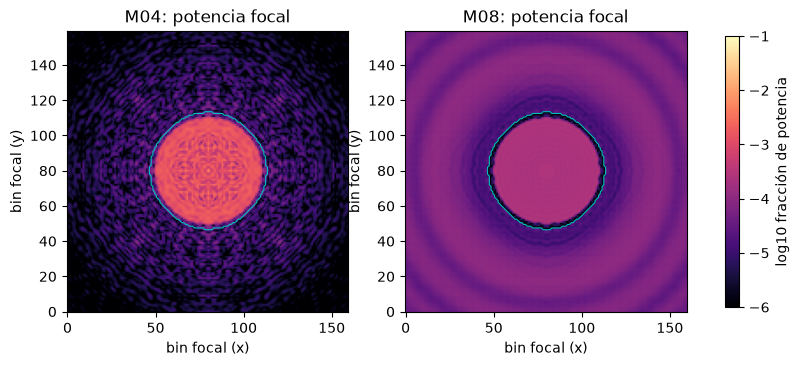

In [7]:
# the focal power of the disc for GS and for MRAF, a window of 160 x 160 bins around the axis, log scale
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
c = setup.n_fft // 2
for ax, name in zip(axes, ("M04", "M08")):
    power = np.abs(forward.fft_focal_field(runs[("disc", name)].phi, setup)) ** 2 * setup.pad**2 / setup.n_pix**2
    window = np.log10(power[c - 80:c + 80, c - 80:c + 80] + 1e-9)
    im = ax.imshow(window, origin="lower", vmin=-6, vmax=-1, cmap="magma")
    ax.contour(shapes["disc"].mask[c - 80:c + 80, c - 80:c + 80], levels=[0.5], colors="c", linewidths=0.8)
    ax.set_title(f"{name}: potencia focal")
    ax.set_xlabel("bin focal (x)")
    ax.set_ylabel("bin focal (y)")
fig.colorbar(im, ax=axes, label="log10 fracción de potencia", shrink=0.8)
plt.show()

Gerchberg-Saxton simple llena el disco con un patrón de ondulaciones que tiene la simetría del SLM, y fuera del contorno hay solo un fondo débil: toda la luz está en la región de señal, y no es plana. MRAF tiene un disco plano con un borde limpio y llena la región fuera del contorno con anillos de luz tenue varias veces más débil que el disco en la escala logarítmica, que es la región de ruido en acción. Esa luz no se desperdicia por accidente: es adonde va la luz que el disco plano no puede usar. La figura no muestra que el perfil sea plano hasta un número dado, lo que sí hace el error, ni lo que harían los anillos en un experimento: un potencial hecho del disco y un halo no es el potencial del disco.

La segunda figura tiene dos paneles. A la izquierda, el error (rojo, eje izquierdo, logarítmico) y la potencia en la señal (azul, eje derecho) contra el parámetro de mezcla para el disco. A la derecha, el error contra la iteración para Gerchberg-Saxton y MRAF.

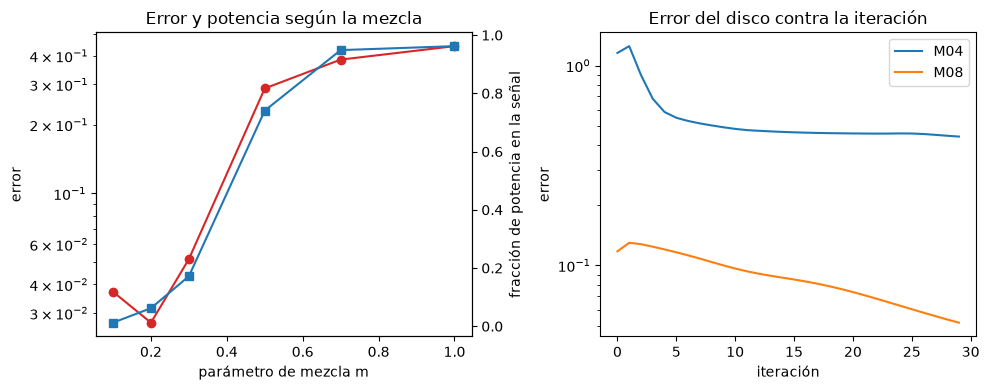

In [8]:
# left: error and efficiency against the mixing parameter; right: the error of the disc against the iteration
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
mixes = sorted(sweep)
ax1.semilogy(mixes, [sweep[m][0] for m in mixes], "o-", color="C3", label="error")
ax1.set_xlabel("parámetro de mezcla m")
ax1.set_ylabel("error")
twin = ax1.twinx()
twin.plot(mixes, [sweep[m][1] for m in mixes], "s-", color="C0", label="fracción de potencia en la señal")
twin.set_ylabel("fracción de potencia en la señal")
ax1.set_title("Error y potencia según la mezcla")
for name in ("M04", "M08"):
    ax2.semilogy([h["error"] for h in runs[("disc", name)].history], label=name)
ax2.set_xlabel("iteración")
ax2.set_ylabel("error")
ax2.set_title("Error del disco contra la iteración")
ax2.legend()
fig.tight_layout()
plt.show()

A la izquierda, ambas curvas suben con $m$: de 0,2 a 0,7 la potencia en la señal pasa de 0,0621 a 0,9485 y el error de 0,0272 a 0,3852, de modo que toda ganancia de eficiencia cuesta precisión, y con $m = 1$ el método es Gerchberg-Saxton simple con su error de 0,4411 y su 0,9621 de la potencia en la región de señal. El error no es monótono en el extremo bajo: con $m = 0,1$ es 0,0371 y la región de señal tiene solo 0,0123 de la potencia, de modo que el error más bajo del recorrido está en $m = 0,2$, donde el método ya es 12 veces menos eficiente que con $m = 0,5$. A la derecha el error de Gerchberg-Saxton se estanca cerca de 0,44 tras 15 iteraciones, mientras el de MRAF es menor desde la primera iteración y sigue bajando en la 30, de 0,118 en la primera a 0,052 en la trigésima. Las figuras no dicen si más iteraciones seguirían mejorando MRAF, porque el presupuesto se detiene en 30.

## Estado del arte

slmsuite es una biblioteca de Python de código abierto para calcular hologramas en SLM, y su MRAF es la referencia que ejecutan quienes usan el campo para potenciales moldeados. En su `Hologram` la amplitud objetivo es un arreglo sobre la grilla de Fourier con relleno, un píxel igual a NaN es una región de ruido, y la opción `mraf_factor` multiplica la región de ruido por un número. Con la notación de la sección Método, slmsuite conserva la amplitud de señal y escala la región de ruido, que es la mezcla $m$ de DinHot con el factor $(1-m)/m$; para $m = 0,3$ el factor es 7/3. Todo lo demás queda en el valor por defecto de slmsuite. Las entradas son las del producto: la misma región de señal, el mismo haz gaussiano normalizado, 30 iteraciones y, en la primera corrida, el mismo inicio de Fresnel que M08, pasado con el argumento `phase`.

La celda ejecuta el MRAF de slmsuite en el disco y en el anillo e imprime, junto a los números de M08 de la sección Método, el error y la potencia en la señal de cada uno.

In [9]:
# slmsuite's MRAF on both shapes: noise region = NaN, factor (1 - m) / m for m = 0.3, the Fresnel start of M08
x, y = geometry.slm_grid(setup)
fresnel = 2 * np.pi * 20.0 * (x**2 + y**2) / (setup.n_pix * setup.pitch_m / 2) ** 2
beam = geometry.input_amplitude(setup)
factor = (1 - 0.3) / 0.3
slm = {}
for shape, target in shapes.items():
    goal = np.where(target.mask, target.amplitude, np.nan)
    holo = Hologram(goal, slm_shape=(setup.n_pix, setup.n_pix), amp=beam, phase=fresnel.copy())
    holo.optimize(method="GS", maxiter=30, verbose=False, mraf_factor=factor)
    slm[shape] = np.array(holo.get_phase(), dtype=float)
    ours = shape_numbers(runs[(shape, "M08")].phi, target, setup)
    theirs = shape_numbers(slm[shape], target, setup)
    print(f"{shape} M08: error = {ours[0]:.4f}, fracción de potencia en la señal = {ours[1]:.4f}")
    print(f"{shape} slmsuite: error = {theirs[0]:.4f}, fracción de potencia en la señal = {theirs[1]:.4f}")

disc M08: error = 0.0517, fracción de potencia en la señal = 0.1719
disc slmsuite: error = 0.0517, fracción de potencia en la señal = 0.1719
ring M08: error = 0.0373, fracción de potencia en la señal = 0.1814
ring slmsuite: error = 0.0373, fracción de potencia en la señal = 0.1814


Quien no precondiciona obtiene el inicio propio de slmsuite, una fase aleatoria. La celda ejecuta ese caso en el disco, sembrado, e imprime los mismos dos números.

In [10]:
# slmsuite from its own default start, a random phase, on the disc: what a user gets without preconditioning
np.random.seed(seed)
goal = np.where(shapes["disc"].mask, shapes["disc"].amplitude, np.nan)
holo = Hologram(goal, slm_shape=(setup.n_pix, setup.n_pix), amp=beam)
holo.optimize(method="GS", maxiter=30, verbose=False, mraf_factor=factor)
slm_random = np.array(holo.get_phase(), dtype=float)
err, eff = shape_numbers(slm_random, shapes["disc"], setup)
print(f"slmsuite, inicio aleatorio: error = {err:.4f}, fracción de potencia en la señal = {eff:.4f}")

slmsuite, inicio aleatorio: error = 0.2866, fracción de potencia en la señal = 0.1774


La figura compara el error de la forma para Gerchberg-Saxton simple, el MRAF del producto y el MRAF de slmsuite, en ambas formas, en un eje logarítmico.

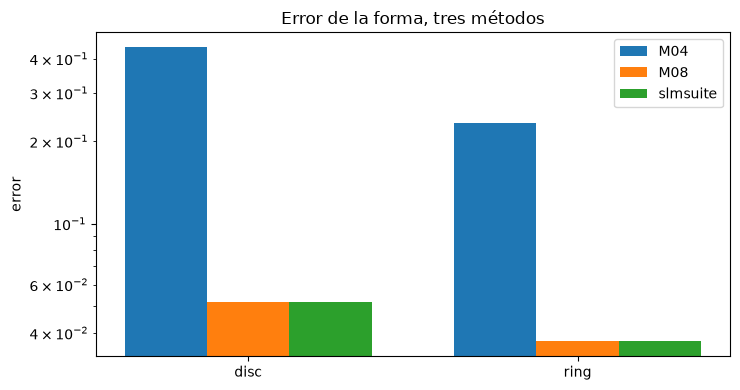

In [11]:
# the error of the shape for GS, the product's MRAF and slmsuite's MRAF, on both shapes, log axis
fig, ax = plt.subplots(figsize=(7.5, 4))
width = 0.25
rows = (("M04", {k: runs[(k, "M04")].phi for k in shapes}), ("M08", {k: runs[(k, "M08")].phi for k in shapes}),
        ("slmsuite", slm))
for k, (label, phis) in enumerate(rows):
    errors = [shape_numbers(phis[shape], shapes[shape], setup)[0] for shape in shapes]
    ax.bar(np.arange(2) + (k - 1) * width, errors, width, label=label)
ax.set_yscale("log")
ax.set_xticks(range(2), list(shapes))
ax.set_ylabel("error")
ax.set_title("Error de la forma, tres métodos")
ax.legend()
fig.tight_layout()
plt.show()

Las barras de M08 y del MRAF de slmsuite tienen la misma altura en ambas formas, y ambas quedan muy bajo Gerchberg-Saxton simple, cuyas barras son 0,4411 en el disco y 0,2340 en el anillo. La coincidencia es el punto: el MRAF del producto es el estado del arte tal como lo implementa la biblioteca, cuando ambos parten de la misma fase, y la diferencia de 0,2866 frente a 0,0517 en el disco entre el inicio aleatorio de slmsuite y el inicio de Fresnel dice que el inicio es lo que debe elegir quien usa el método. La figura compara una mezcla y 30 iteraciones, y no dice cómo se comporta cada implementación con los otros valores de la mezcla recorridos arriba.

## Resultados

**Respuesta:** MRAF compra precisión con eficiencia, y el parámetro de mezcla fija el precio, en el producto y en slmsuite por igual. Con la mezcla de 0,3 del producto el error del perfil baja de 0,4411 a 0,0517 en el disco, un factor de 8,5, y de 0,2340 a 0,0373 en el anillo, un factor de 6,3, mientras la fracción de la potencia de entrada en la región de señal baja de 0,9621 a 0,1719 en el disco y de 0,9632 a 0,1814 en el anillo. A lo largo del recorrido en el disco el error es 0,0272 con $m = 0,2$ y 0,0621 de la potencia en la región de señal, y 0,2882 con $m = 0,5$ y 0,7407; no sigue bajando bajo $m = 0,2$, pues con $m = 0,1$ es 0,0371. El inicio importa tanto como la mezcla: desde una fase aleatoria el mismo método obtiene un error de 0,3004 en vez de 0,0517. Ejecutado con slmsuite 0.5.0 desde el mismo inicio y con el factor 7/3, MRAF da los mismos números a cuatro dígitos (0,0517 y 0,1719 en el disco, 0,0373 y 0,1814 en el anillo), y desde el inicio aleatorio propio de slmsuite el error del disco es 0,2866. Un potencial moldeado preciso de este método es entonces un potencial que desperdicia la mayor parte de su luz, y el experimento tiene que tener la potencia de sobra.

## Resumen

Gerchberg-Saxton no puede hacer un disco plano porque no tiene dónde poner la luz que el disco no quiere; MRAF le da una región de ruido, y el disco plano sigue al precio de cinco sextos de la potencia. El parámetro de mezcla se mueve a lo largo de ese intercambio, con una mejor precisión cerca de $m = 0,2$ en esta grilla y un colapso de la ventaja sobre $m = 0,5$, y el inicio suave es parte del método. El notebook siguiente pregunta si un mejor inicio, una fase de transporte óptimo, cambia el precio.

## Referencias

- Pasienski y DeMarco, "A high-accuracy algorithm for designing arbitrary holographic atom traps", Optics Express 16, 2176 (2008), https://doi.org/10.1364/OE.16.002176.
- Di Leonardo, Ianni y Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.
- slmsuite 0.5.0 (MIT), https://pypi.org/pypi/slmsuite/json and https://pypi.org/project/slmsuite/.